# Clasificación de perros y gatos con CNN y transferencia

Proyecto de Inteligencia Artificial de U-tad. Compara una CNN propia ajustada con Hyperband con EfficientNetB0, congelada y con ajuste fino.
La [guía de ejecución](../README.md#run-the-notebooks) explica cómo cargar imágenes propias o autorizadas.

# Nota: estructura del documento
- El trabajo lo he dividido en varias partes, por un lado el entrenamiento de las CNNs y por otro la validación (conclusiones, gráficos, matriz de confusión, etc.)

1. Entrenamiento de CNNs. La estructura de esta parte es la siguiente:
   * De manera general: split 90/10 para el dataset, usando `train_test_split` de scikit-learn
   * Para la CNN desde 0:
       * Data augmentation y visualización de los datos aumentados
       * La última CNN que hice de manera manual antes de empezar con hypertuning
       * La función de hypertuning y los hiperparámetros que prueba
       * Uso de HyperBand para la búsqueda de los hiperparámetros y los resultados
       * Entrenamiento de la CNN seleccionada por el tuner
   * Para la CNN aplicando transfer learning:
       * Elección del modelo (EfficientNetB0)
       * Data augmentation para el transfer learning
       * Entrenamiento del modelo
       * Fine-tuning del modelo descongelando las últimas capas.

2. Conclusiones del entrenamiento de las CNNs:
   * Test sobre los datos del split inicial
   * Gráficas del progreso del `accuracy` y `loss`, una para cada CNN
   * Matrices de confusión sobre las CNN desde 0, la de transfer learning y el fine-tuning
   * Imágenes de las arquitecturas de los modelos (también adjuntas en la entrega)
   * Prueba con imágenes externas al dataset dado para ver el desempeño del modelo con imágenes fuera del dataset
   * Generación del CSV devuelto

* El entrenamiento original se ejecutó en Kaggle con GPU. Las figuras y métricas conservan los resultados de esa ejecución.


In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Añade aquí los import que utilices en tu código
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

# Callbacks
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
# Para generar y guardar el diagrama
from tensorflow.keras.utils import plot_model
# Para la matriz de confusion
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Para la creación del hypermodelo
import keras_tuner as kt
# Para el fragemento de código de elegir una imagen al azar y mostrar la activación
import random


from PIL import Image
import pandas as pd

# Para hacer el train test split he usado sckit-learn
from sklearn.model_selection import train_test_split 

plt.rcParams['figure.figsize'] = (12, 6)
np.random.seed(33)
tf.random.set_seed(33)

## Carga de Imágenes

Se cargan exactamente **1000 imágenes de cada clase** desde la carpeta `Cats_Dogs`, asumiendo esta estructura:

```text
Cats_Dogs/
├─ cat/
│  ├─ 0.jpg
│  ├─ ...
├─ dog/
│  ├─ 0.jpg
│  ├─ ...
```

Preprocesamiento:
- Redimensionado a `224×224` píxeles (puedes cambiar `IMG_SIZE` si lo justificas).
- Conversión a RGB.

Las etiquetas se almacenan como enteros:
- `0` → gato  
- `1` → perro

In [ ]:
# Configuración de rutas y parámetros
# 'Cats_Dogs' si se ejecuta en local
DATASET_DIR = Path(os.environ.get("CATS_DOGS_DIR", PROJECT_ROOT / "data" / "Cats_Dogs"))
CATEGORIES = ["cat", "dog"]
IMG_SIZE = (224, 224)

X = []
y = []

# Cargar imágenes y etiquetas
for label, category in enumerate(CATEGORIES):
    folder_path = os.path.join(DATASET_DIR, category)
    for file in os.listdir(folder_path):
        img_path = os.path.join(folder_path, file)
        try:
            img = Image.open(img_path).convert("RGB")
            img = img.resize(IMG_SIZE)
            X.append(np.array(img))
            y.append(label)
        except Exception as e:
            print("Error al cargar:", img_path, e)

# Conversión a arrays
X = np.array(X, dtype="float32")
y = np.array(y, dtype="int32")

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

## Desarrollo de la Práctica: CNN desde cero

### Split
Dado el bajo numero de imagenes he aplicado un 90/10 split (1800/200) para el test final

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.1)

### Preprocesado
Para el preprocesado de las imagenes:
1. He decidido normalizar los valores de los pixeles (Despues en la creacion del modelo con la capa `layers.Rescaling(1./255)`
2. Dejar la sigmoide con clasificación binaria 
3. Y finalmente data augmentation

In [ ]:
# Normalización para las imagenes del ejemplo
X_train_normalized = X_train.astype("float32") / 255.0

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"), # Voltea horizontal
    layers.RandomRotation(0.2), # Rotaciones de hasta un 20%
    layers.RandomZoom(0.2), # Zoom de hasta 20%
    layers.RandomContrast(0.1), # +- contraste
    layers.RandomTranslation(0.1, 0.1), # Desplazamiento aleatorio
    layers.RandomBrightness(0.2, value_range=[0.0, 1.0]), # variaciones de brillo
], "data_augmentation")


# Visualización de ejemplos aumentados
sample_images = X_train_normalized[:5]
augmented_images = data_augmentation(sample_images)
augmented_images = tf.clip_by_value(augmented_images, 0.0, 1.0)


fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i in range(5):
    axes[0, i].imshow(sample_images[i])
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")
    axes[1, i].imshow(augmented_images[i])
    axes[1, i].set_title("Aumentada")
    axes[1, i].axis("off")

plt.suptitle("Ejemplos de Data Augmentation en el dataset")
plt.tight_layout()
plt.show()



### A continuacion el ultimo modelo que hice manualmente antes de empezar con HyperparameterTunning
- El modelo tiene estas características: `accuracy: 0.7144 - loss: 0.5341 - val_accuracy: 0.6531 - val_loss: 0.6482`
- Los resultados que me dio Loss test: `0.6188 | Acc test: 0.6525` al pasarlos por `y_test`
- Es el fichero adjunto `cnn_manual.keras`

In [ ]:
input_shape = IMG_SIZE + (3,)

model_manual = models.Sequential([
    # Entrada
    keras.Input(shape=input_shape),

    # Data augmentation
    data_augmentation,

    # Bloque 1
    layers.Conv2D(16, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(16, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),
    

    # Bloque 2
    layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.3),

    # Bloque 3
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.2),

    # Clasificación 
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model_manual.summary()


### Hyperparameter tunning 
- Despues de mucha prueba y error, he acabado optando por hacer HyperParameter tunning para automatizar y encontrar el mejor modelo 
    - Para ello me he basado en la documentacion del tuner de Keras: https://www.tensorflow.org/tutorials/keras/keras_tuner?hl=es-419
    - Este ejemplo de neptune AI: https://neptune.ai/blog/keras-tuner-tuning-hyperparameters-deep-learning-model
    - Y el ejemplo 4.4 de los notebooks de clase 

#### Definición de la función para construir el modelo

- He creado una función que crea una serie de bloques de convolución y prueba con distintos hiperparámetros para obtener los mejores resultados

  1. Número de bloques CONV->BN->CONV->BN->MP
  2. Número de filtros iniciales. Por cada bloque los duplicamos por 2 (p. ej.: 16 -> 32 -> 64 -> etc.)
  3. El dropout de los bloques. Por cada bloque, lo aumentamos en un porcentaje de 10% en 10%
        - La idea es que a medida que la red se vuelve más profunda, para no memorizar el ruido, aplicamos un mayor dropout
  4. Decidir si usar GlobalAvgPooling o Flatten
  5. Neuronas de la capa densa a probar en el bloque de clasificación
  6. Dropout en la capa final
  7. Elegir el learning rate más adecuado
  8. Elegir el tamaño del kernel de convolución (3x3 o 5x5)
  9. Elegir la activación entre ReLU o LeakyReLU
  10. Decidir opcionalmente si usar BatchNormalization por bloque
  11. Decidir el tamaño del MaxPooling por bloque (2 o 3)



In [ ]:
def build_model(hp):
    
    # Hiperparámetros de la Arquitectura 
    hp_num_blocks = hp.Int('num_blocks', min_value=2, max_value=4, step=1)  # Número de Bloques CONV->BN->CONV->BN->MP
    hp_base_filters = hp.Choice('base_filters', values=[16,32])  # Número de filtros con los que empezar
    hp_dense_units = hp.Choice('dense_units', values=[64, 128, 256])  # Nº de neuronas de la capa densa
    hp_dropout_dense = hp.Float('dropout_dense', min_value=0.3, max_value=0.5, step=0.1)  # Dropout tras la capa densa
    hp_use_flatten_instead_of_global_avg_pooling_2d = hp.Boolean('use_flatten_instead_of_global', default=False)  # Prueba entre Flatten y GlobalAveragePooling2D

    # Nuevos hiperparámetros kernel 
    hp_kernel_size = hp.Choice('kernel_size', values=[3, 5])  # tamaño del kernel (3x3 o 5x5)
    hp_activation = hp.Choice('activation', values=['relu', 'leaky'])  # elegir entre ReLU o LeakyReLU

    # Hiperparámetros de Compilación 
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-3, 5e-4, 1e-4])

    model = models.Sequential()
    
    # Entrada y Normalización/Data Augmentation
    model.add(keras.Input(shape=IMG_SIZE + (3,)))
    model.add(layers.Rescaling(1./255))
    model.add(data_augmentation) 
    
    # Creacion de los bloques de CONV
    for i in range(hp_num_blocks):
        # El número de filtros se duplica en cada bloque
        current_filters = hp_base_filters * (2 ** i)

        # Hiperparametros por bloque i
        hp_use_bn = hp.Boolean(f"use_bn_{i}", default=True)
        hp_dropout_value = hp.Choice(f"dropout_{i}", values=[0.1, 0.2, 0.3])

        # Nuevo: tamaño de pooling por bloque
        hp_pool_size = hp.Int(f"pool_size_{i}", min_value=2, max_value=3, step=1)

        # Bloque CONV (Doble Conv2D + BN opcional + Activación + Pool + Dropout)
        # Usamos kernel_size elegido globalmente
        k = (hp_kernel_size, hp_kernel_size)

        # 1ª Conv
        model.add(layers.Conv2D(current_filters, k, activation=None, padding='same'))
        if hp_use_bn:
            model.add(layers.BatchNormalization())
        # Activación escogida
        if hp_activation == 'leaky':
            model.add(layers.LeakyReLU())
        else:
            model.add(layers.Activation('relu'))

        # 2ª Conv
        model.add(layers.Conv2D(current_filters, k, activation=None, padding='same'))
        if hp_use_bn:
            model.add(layers.BatchNormalization())
        if hp_activation == 'leaky':
            model.add(layers.LeakyReLU())
        else:
            model.add(layers.Activation('relu'))

        # Pooling (size variable por bloque)
        model.add(layers.MaxPooling2D(pool_size=(hp_pool_size, hp_pool_size)))
        
        # Regularización (Dropout)
        # Aumentar el Dropout en bloques posteriores para una mejor regularización
        model.add(layers.Dropout((hp_dropout_value * (1 + i * 0.1))))

    # Clasificación Final (Fija)
    if hp_use_flatten_instead_of_global_avg_pooling_2d:
        model.add(layers.Flatten())
    else:
        model.add(layers.GlobalAveragePooling2D())
        
    model.add(layers.Dense(hp_dense_units, activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(hp_dropout_dense))
    model.add(layers.Dense(1, activation='sigmoid'))
    
    # Compilación
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=hp_learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    
    return model


#### Uso de HyperBand en Keras tuner para buscar los mejores hiperparámetros


- Del mismo articulo de tensorflow he optado por usar `HyperBand`

In [ ]:
tuner = kt.Hyperband(
    build_model,
    objective='val_accuracy',
    max_epochs=50,
    factor=4,
    directory='tuner_logs',
    project_name='cats_dogs_tuning_v5'
)

stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)


tuner.search(
    X_train, y_train,
    epochs=60,
    validation_split=0.2,
    callbacks=[stop_early],
    verbose=1,
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
best_model_tuner = tuner.get_best_models(num_models=1)[0]

In [ ]:
# --- Imprime resumen de hiperparámetros principales ---
print(f"Número de Bloques (num_blocks): {best_hps.get('num_blocks')}")
print(f"Filtros Base (base_filters): {best_hps.get('base_filters')}")
print(f"Unidades de Capa Densa (dense_units): {best_hps.get('dense_units')}")

# Regularización (dropout en la densa)
dropout_dense = best_hps.get('dropout_dense')
if dropout_dense is not None:
    print(f"Dropout en Capa Densa (dropout_dense): {dropout_dense:.2f}")
else:
    print("Dropout en Capa Densa (dropout_dense): no especificado en best_hps")

# Flatten o GlobalAvgPooling2D
use_flatten = best_hps.get('use_flatten_instead_of_global')
print(f"Uso de Flatten (True) en vez de GlobalAvgPooling (False): {use_flatten}")

# Optimización
print(f"Tasa de Aprendizaje (learning_rate): {best_hps.get('learning_rate')}")

# Kernel y Activación globales
print(f"Tamaño de Kernel (kernel_size): {best_hps.get('kernel_size')}")
print(f"Activación (activation): {best_hps.get('activation')}")

# --- Detalle por bloque (use_bn, dropout por bloque, pool_size y dropout efectivo) ---
num_blocks = best_hps.get('num_blocks') or 0
base_filters = best_hps.get('base_filters') or 0

print("\n--- Detalle por bloque ---")
for i in range(num_blocks):
    use_bn_key = f"use_bn_{i}"
    dropout_key = f"dropout_{i}"
    pool_key = f"pool_size_{i}"

    use_bn = best_hps.get(use_bn_key)
    base_dropout = best_hps.get(dropout_key)
    pool_size = best_hps.get(pool_key)

    # Calcula dropout efectivo según tu fórmula: base_dropout * (1 + i*0.1)
    if base_dropout is not None:
        effective_dropout = base_dropout * (1 + i * 0.1)
        effective_dropout_str = f"{effective_dropout:.3f}"
    else:
        effective_dropout_str = "n/a"

    filters_this_block = base_filters * (2 ** i) if base_filters else "n/a"

    print(f"Bloque {i}: filtros={filters_this_block}, use_bn={use_bn}, "
          f"dropout_base={base_dropout}, dropout_efectivo={effective_dropout_str}, "
          f"pool_size={pool_size}")


In [ ]:
# Compilación del modelo
best_model_tuner.compile(
    optimizer=keras.optimizers.Adam(learning_rate=best_hps.get('learning_rate')),
    loss='binary_crossentropy',
    metrics=['accuracy']
)


# Definición de callbacks
callbacks = [
   ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.9,
        patience=5,
        verbose=0
    ),
    ModelCheckpoint(
        filepath='cnn_hypermodelo.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=0
    ),
    EarlyStopping(
        monitor='val_loss',
        patience=20,
        restore_best_weights=True,
        verbose=0
    )
]

best_model_tuner.summary()

In [ ]:
history_tuner = best_model_tuner.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

In [ ]:
best_acc = max(history_tuner.history['accuracy'])  
best_epoch_acc = history_tuner.history['accuracy'].index(best_acc) + 1
print(f"Mejor accuracy: {best_acc:.4f} en la época {best_epoch_acc}")

best_loss = min(history_tuner.history['loss']) 
best_epoch_loss = history_tuner.history['loss'].index(best_loss) + 1
print(f"Mejor loss: {best_loss:.4f} en la época {best_epoch_loss}")
best_epoch_acc = history_tuner.history['accuracy'].index(best_acc) + 1


best_acc = max(history_tuner.history['val_accuracy'])  
best_epoch_acc = history_tuner.history['val_accuracy'].index(best_acc) + 1
print(f"Mejor accuracy: {best_acc:.4f} en la época {best_epoch_acc}")

best_loss = min(history_tuner.history['val_loss']) 
best_epoch_loss = history_tuner.history['val_loss'].index(best_loss) + 1
print(f"Mejor loss: {best_loss:.4f} en la época {best_epoch_loss}")


## Desarrollo de la practica: Transfer-learning y finetunning de una CNN

In [ ]:
# En mi caso tras comparar entre los modelos de preentrenados de keras (https://keras.io/api/applications/) me he decantado por EfficientNetB0 
# dado que su tamaño de entrada es el mismo con el he estado trabajando (224x224)

from tensorflow.keras.applications import EfficientNetB0

### Transfer learning

In [ ]:
# Cargar modelo base adaptado a 224x224 eliminando las capas finales de clasificación (include_top=false)
EffiNet_model = EfficientNetB0(include_top=False, weights='imagenet', input_shape=(IMG_SIZE + (3,)))

# Transfer learning
EffiNet_model.trainable = False


data_augmentation_tl = keras.Sequential([
    layers.RandomFlip("horizontal"), # Voltea horizontal
    layers.RandomRotation(0.1), # Rotaciones de hasta un 20%
    layers.RandomZoom(0.1), # Zoom de hasta 20%
    layers.RandomContrast(0.1), # +- contraste
])


transfer_model = keras.Sequential([
    keras.Input(shape=IMG_SIZE + (3,)),
    data_augmentation_tl,
    EffiNet_model,                          # Base congelada
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),    
    layers.Dense(1, activation='sigmoid')
])

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary(show_trainable=True)

In [ ]:
callbacks_tl = [
    ReduceLROnPlateau(
        monitor='val_loss', 
        factor=0.5, 
        patience=3, 
        min_lr=1e-7,
        verbose=0
    ),
    EarlyStopping(
        monitor='val_loss', 
        patience=5,  
        restore_best_weights=True, 
        verbose=0
    ),
    ModelCheckpoint(
        'effinet_transfer.keras', 
        monitor='val_accuracy', 
        save_best_only=True, 
        verbose=0
    )
]

history_transfer = transfer_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    callbacks=callbacks_tl,
    verbose=1
)

In [ ]:
transfer_base_test_loss, transfer_base_test_acc = transfer_model.evaluate(X_test, y_test, verbose=0)
print(f"[Transfer Base] Test Loss: {transfer_base_test_loss:.4f} | Test Accuracy: {transfer_base_test_acc:.4f}")


### Fine tunning

In [ ]:
# Descongelar parte de  (por ejemplo, las últimas  capas)
EffiNet_model = transfer_model.layers[1]  #  está en la primera posición del Sequential
EffiNet_model.trainable = True

# Congelar las capas inferiores
for layer in EffiNet_model.layers[:-30]:
    layer.trainable = False

print(f"Número de capas entrenables: {len([l for l in EffiNet_model.layers if l.trainable])}, Numero de capas:{len(EffiNet_model.layers)}")

# 
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
callbacks_fine = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=0),
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=0),
    ModelCheckpoint('effinet_finetuned.keras', monitor='val_accuracy', save_best_only=True, verbose=0)
]

history_fine = transfer_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=30,
    callbacks=callbacks_fine,
    verbose=1
)

## Conclusiones, graficos, matrices de confusion e imagenes de la arquitectura de los modelos entrenados

### Evaluacion de los dos modelos creados (La CNN desde cero y la de transfer learning con fine tuning)

In [64]:

# Evaluación del mejor modelo del tuning (búsqueda de hiperparámetros)
hypermodel_test_loss, hypermodel_test_acc = best_model_tuner.evaluate(X_test, y_test, verbose=0)
print(f"Test en el mejor modelo de búsqueda de hiperparámetros: Loss = {hypermodel_test_loss:.4f} | Acc = {hypermodel_test_acc:.4f}")

# Evaluación del modelo de transfer learning
print(f"[Transfer Base] Test Loss: {transfer_base_test_loss:.4f} | Test Accuracy: {transfer_base_test_acc:.4f}")


# Evaluación del modelo de transfer learning con fine-tuning
transfer_ft_test_loss, transfer_ft_test_acc = transfer_model.evaluate(X_test, y_test, verbose=0)
print(f"[Transfer Fine-Tuning] Test Loss: {transfer_ft_test_loss:.4f} | Test Accuracy: {transfer_ft_test_acc:.4f}")


Test en el mejor modelo de búsqueda de hiperparámetros: Loss = 0.2925 | Acc = 0.8900
[Transfer Base] Test Loss: 0.0199 | Test Accuracy: 0.9950
[Transfer Fine-Tuning] Test Loss: 0.0178 | Test Accuracy: 0.9900


### Grafica comparativa de las predicciones aplicando Hyperparameter tunning

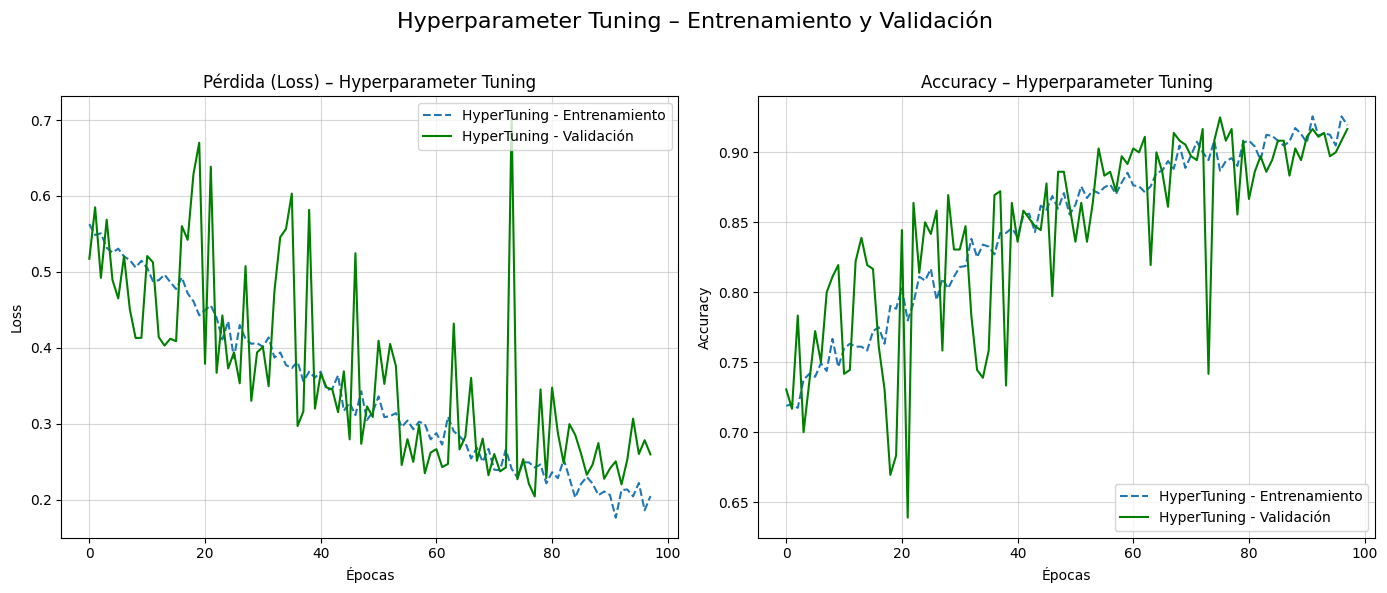

In [65]:
plt.figure(figsize=(14, 6))

# --- 1. Pérdida (Loss) ---
plt.subplot(1, 2, 1)
plt.plot(history_tuner.history['loss'], label='HyperTuning - Entrenamiento', linestyle='--')
plt.plot(history_tuner.history['val_loss'], label='HyperTuning - Validación', color='green')

plt.title('Pérdida (Loss) – Hyperparameter Tuning')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.5)

# --- 2. Accuracy ---
plt.subplot(1, 2, 2)
plt.plot(history_tuner.history['accuracy'], label='HyperTuning - Entrenamiento', linestyle='--')
plt.plot(history_tuner.history['val_accuracy'], label='HyperTuning - Validación', color='green')

plt.title('Accuracy – Hyperparameter Tuning')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.5)

plt.suptitle('Hyperparameter Tuning – Entrenamiento y Validación', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


### Grafica comparativa de las predicciones aplicando Transfer Learning vs Fine tunning

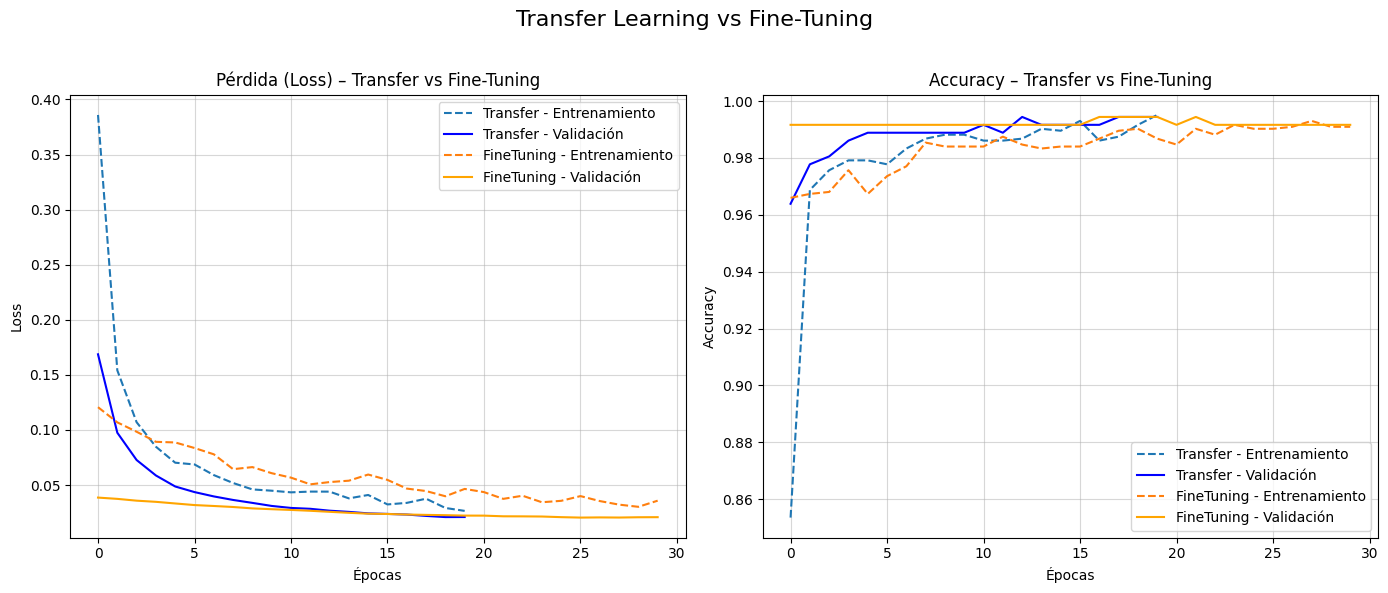

In [66]:
plt.figure(figsize=(14, 6))

# --- 1. Pérdida (Loss) ---
plt.subplot(1, 2, 1)
plt.plot(history_transfer.history['loss'], label='Transfer - Entrenamiento', linestyle='--')
plt.plot(history_transfer.history['val_loss'], label='Transfer - Validación', color='blue')

plt.plot(history_fine.history['loss'], label='FineTuning - Entrenamiento', linestyle='--')
plt.plot(history_fine.history['val_loss'], label='FineTuning - Validación', color='orange')

plt.title('Pérdida (Loss) – Transfer vs Fine-Tuning')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.5)

# --- 2. Accuracy ---
plt.subplot(1, 2, 2)
plt.plot(history_transfer.history['accuracy'], label='Transfer - Entrenamiento', linestyle='--')
plt.plot(history_transfer.history['val_accuracy'], label='Transfer - Validación', color='blue')

plt.plot(history_fine.history['accuracy'], label='FineTuning - Entrenamiento', linestyle='--')
plt.plot(history_fine.history['val_accuracy'], label='FineTuning - Validación', color='orange')

plt.title('Accuracy – Transfer vs Fine-Tuning')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.5)

plt.suptitle('Transfer Learning vs Fine-Tuning', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


### Matriz de confusion para los modelos

- Nota: dado que el accuracy del transfer learning ya era bastante alto, el fine tuning no ha tenido beneficios sobre el accuracy 

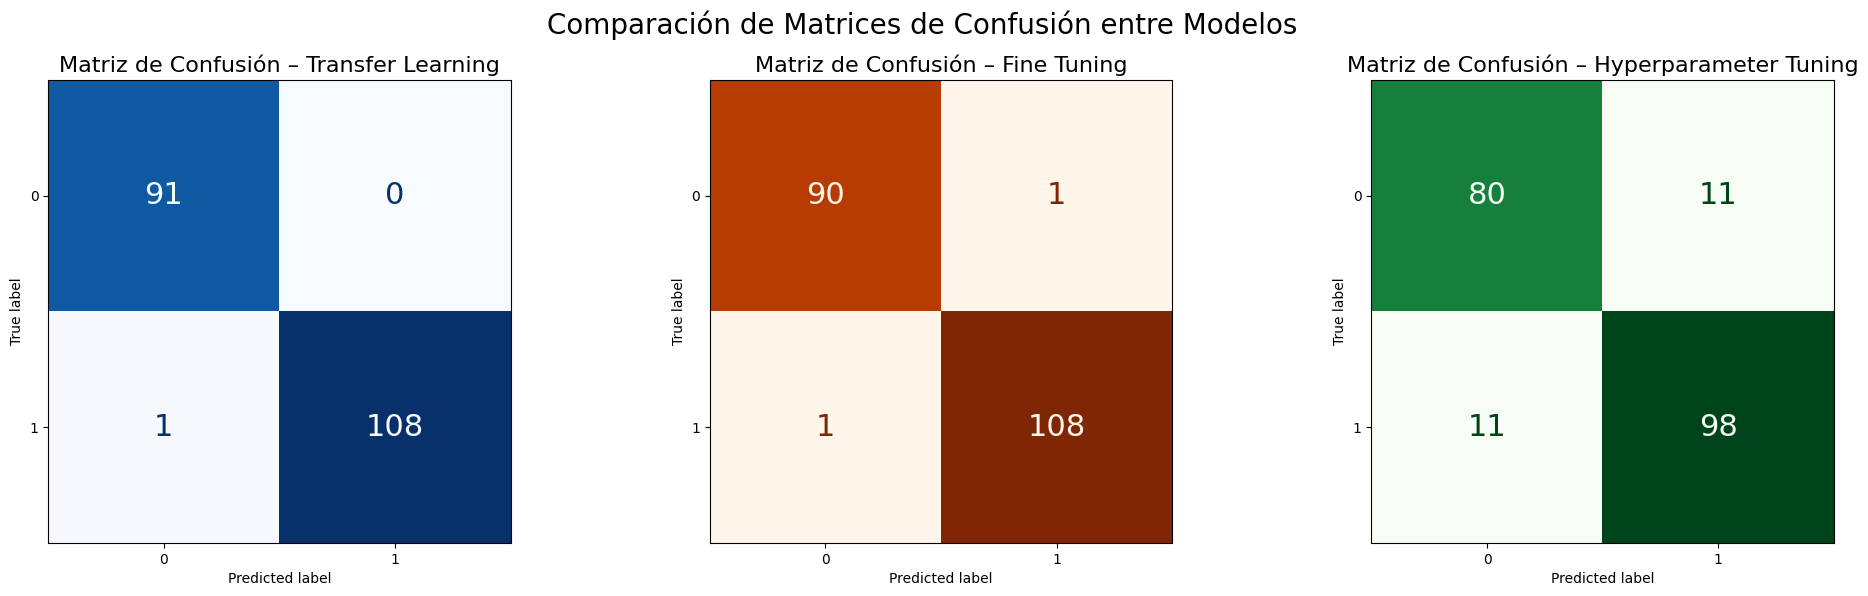

In [67]:
# 1. Cargar modelos

# Mejor modelo del Hyperparameter Tuning
hypermodel_best = best_model_tuner

# Modelo base de Transfer Learning, sin fine-tuning, como al hacer fine tuning se 'sobreescribe', lo he guardado antes y lo cargo ahora para comparar
transfer_base_model = keras.models.load_model("effinet_transfer.keras")

# Modelo con Fine-Tuning
transfer_fine_model = transfer_model


# 2. Predicciones en test
y_true = y_test

# Convertimos probabilidades a etiquetas 0/1
y_pred_transfer = (transfer_base_model.predict(X_test, verbose=0) > 0.5).astype(int).flatten()
y_pred_fine = (transfer_fine_model.predict(X_test, verbose=0) > 0.5).astype(int).flatten()
y_pred_hyper = (hypermodel_best.predict(X_test, verbose=0) > 0.5).astype(int).flatten()

# 3. Matrices de confusión

cm_transfer = confusion_matrix(y_true, y_pred_transfer)
cm_fine = confusion_matrix(y_true, y_pred_fine)
cm_hyper = confusion_matrix(y_true, y_pred_hyper)

# 4. Visualización

fig, ax = plt.subplots(1, 3, figsize=(20, 6))

disp1 = ConfusionMatrixDisplay(cm_transfer).plot(ax=ax[0], cmap="Blues", colorbar=False)
disp2 = ConfusionMatrixDisplay(cm_fine).plot(ax=ax[1], cmap="Oranges", colorbar=False)
disp3 = ConfusionMatrixDisplay(cm_hyper).plot(ax=ax[2], cmap="Greens", colorbar=False)

# Aumentar font-size de los números dentro de las matrices
for disp in [disp1, disp2, disp3]:
    for text in disp.text_.ravel():
        text.set_fontsize(22) 

ax[0].set_title("Matriz de Confusión – Transfer Learning", fontsize=16)
ax[1].set_title("Matriz de Confusión – Fine Tuning", fontsize=16)
ax[2].set_title("Matriz de Confusión – Hyperparameter Tuning", fontsize=16)

plt.suptitle("Comparación de Matrices de Confusión entre Modelos", fontsize=20)
plt.tight_layout()
plt.show()

### Comparación de las arquitecturas de los modelos
- Nota: para la imagen del Hypermodelo resultante, como es tan grande he adjuntado la imagen en tamaño completo

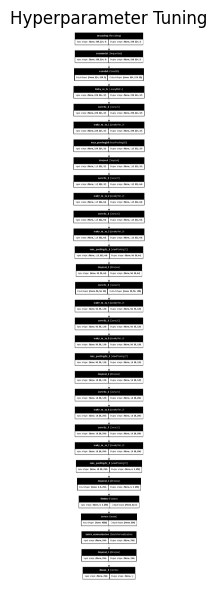

In [68]:
# Instala Graphviz (dot) para generar los diagramas de arquitectura.
from shutil import which

if which("dot"):
    for model, filename in (
        (hypermodel_best, "hypermodel_best.png"),
        (transfer_base_model, "transfer_base_model.png"),
        (transfer_fine_model, "transfer_fine_model.png"),
    ):
        plot_model(model, to_file=filename, show_shapes=True, show_layer_names=True)
    plt.imshow(Image.open("hypermodel_best.png"))
    plt.title("Hyperparameter Tuning")
    plt.axis("off")
    plt.show()
else:
    print("Graphviz no está instalado. Se omiten los diagramas de arquitectura.")

In [ ]:
# Mostrar side-by-side
fig, ax = plt.subplots(1, 2)

ax[0].imshow(img2)
ax[0].set_title("Transfer Learning (Base)")
ax[0].axis("off")

ax[1].imshow(img3)
ax[1].set_title("Transfer Learning (Fine-Tuning)")
ax[1].axis("off")

plt.tight_layout()
plt.show()

### Evaluacion del modelo con imagenes externas
- He descargado de internet 10 imagenes, para evaluar.
- El siguiente código selecciona 3 imagenes a azar y muestra su activación

In [ ]:
# --- Directorio de imágenes externas ---
# 'external-test' si se ejecuta en local
external_dir = Path(os.environ.get("CATS_DOGS_EXTERNAL_DIR", PROJECT_ROOT / "data" / "external-test"))

# Listar archivos de imagen válidos
valid_ext = (".png", ".jpg", ".jpeg", ".bmp", ".tiff")
image_files = [p.name for p in external_dir.glob("*") if p.suffix.lower() in valid_ext]

# Seleccionar 3 imágenes al azar
sample_images = random.sample(image_files, min(3, len(image_files)))
if not sample_images:
    print("Añade imágenes a data/external-test para esta prueba opcional.")

# --- Función para cargar la imagen ---
def load_and_preprocess(path, size=224):
    img = Image.open(path).convert("RGB")
    img = img.resize((size, size))
    arr = np.array(img)  # dtype uint8
    return arr, img

# --- Mostrar resultados ---
for img_name in sample_images:
    img_path = os.path.join(external_dir, img_name)
    arr, pil_img = load_and_preprocess(img_path)
    arr_exp = np.expand_dims(arr, axis=0)  # shape (1, 224, 224, 3)

    # ---- Predicciones ----
    p_base = transfer_base_model.predict(arr_exp, verbose=0)[0][0]
    p_fine = transfer_fine_model.predict(arr_exp, verbose=0)[0][0]
    p_hyper = hypermodel_best.predict(arr_exp, verbose=0)[0][0]

    # Convertir a 0/1
    label_base = int(p_base > 0.5)
    label_fine = int(p_fine > 0.5)
    label_hyper = int(p_hyper > 0.5)

    # ---- Crear figura con imagen a la izquierda y gráficas a la derecha ----
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    # Imagen
    axes[0].imshow(pil_img)
    axes[0].axis("off")
    axes[0].set_title(f"Imagen\n{img_name}", fontsize=12)

    # Gráficas de probabilidades
    # Modelo Base
    axes[1].bar(["Clase 0", "Clase 1"], [1 - p_base, p_base], color="skyblue")
    axes[1].set_ylim(0,1)
    axes[1].set_title(f"Base\nPred: {label_base} | Prob: {p_base:.2f}")
    for i, v in enumerate([1 - p_base, p_base]):
        axes[1].text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=10)

    # Fine-Tuning
    axes[2].bar(["Clase 0", "Clase 1"], [1 - p_fine, p_fine], color="orange")
    axes[2].set_ylim(0,1)
    axes[2].set_title(f"Fine-Tuning\nPred: {label_fine} | Prob: {p_fine:.2f}")
    for i, v in enumerate([1 - p_fine, p_fine]):
        axes[2].text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=10)

    # Hyperparameter Tuning
    axes[3].bar(["Clase 0", "Clase 1"], [1 - p_hyper, p_hyper], color="green")
    axes[3].set_ylim(0,1)
    axes[3].set_title(f"Hyper-Tuning\nPred: {label_hyper} | Prob: {p_hyper:.2f}")
    for i, v in enumerate([1 - p_hyper, p_hyper]):
        axes[3].text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=10)

    plt.suptitle(f"Evaluación de Imagen Externa", fontsize=16)
    plt.tight_layout()
    plt.show()


La prueba opcional compara los tres modelos con imágenes externas elegidas al azar.

### Conclusiones Generales
- Como se puede ver a lo largo del notebook, destacar el contraste de la eficacia de diseñar arquitecturas propias frente a la reutilización de modelos pre-entrenados con más imagenes y más generales. 

- Mientras que la CNN diseñada desde cero me ha requerido hacer un largo proceso de Hyperparameter Tuning (ajustando filtros, dropout y funciones de activación) para elevar su precisión de un 71% inicial a un mucho mejor 89%, la aplicación de Transfer Learning muestra ser muchísimo mejor en eficiencia y resultados, especialmente en datasets y recursos limitados. 

- Utilizando EfficientNetB0, se alcanza una precisión casi perfecta del 99.5% con el modelo base, validando que, para datasets de tamaño limitado (2,000 imágenes), la transferencia de aprendizaje es la mejor manera para minimizar el coste computacional y maximizar el rendimiento.

## Generación del CSV final de Predicciones

Una vez **definido y entrenado tu modelo** (no incluido en esta plantilla) y separadas tus imágenes de prueba en `X_test`, genera el archivo `predicciones_cats_dogs.csv` con el siguiente formato:

```text
id,label
0,0
1,0
2,1
...
```

Donde:
- `id` es el índice (comenzando en 0) de la imagen de prueba.
- `label` es `0` para gato y `1` para perro.

Notas importantes:
- Esta celda asume que tu **modelo** tiene una **salida sigmoide** (`Dense(1, activation='sigmoid')`) y que dispones de un `X_test` con las imágenes de evaluación (preprocesadas igual que X).
- Si usas una salida softmax de 2 neuronas, adapta la conversión de `y_pred` a clases.

- Nota, para las predicciones he usado la CNN desde 0 pero, con el modelo de transfer learning el accuracy sería mayor.

In [ ]:
# Generación de CSV de predicciones
# Requisitos previos:
# - Debes haber definido y entrenado tu 'model'
# - Debes tener preparado 'X_test' con el mismo preprocesamiento (224x224, RGB, normalizado)

# Obtener predicciones del modelo
y_pred = hypermodel_best.predict(X_test, verbose=0)

# Si tu salida es sigmoide (1 neurona → binaria)
y_pred_classes = (y_pred > 0.5).astype("int32").flatten()

# Crear DataFrame con el formato solicitado
df = pd.DataFrame({
    "id": np.arange(1, len(y_pred_classes) + 1),
    "label": y_pred_classes
})

# Guardar como CSV
output_path = "predicciones_cats_dogs.csv"
df.to_csv(output_path, index=False)

print(f"Archivo guardado correctamente como: {output_path}")
df.head()